# 02 · Metrics, cost drivers and exceptions

**Questions:** Where is electricity spending concentrated? What changed year over year, and which records need
investigation?

Effective cost per kWh = **total dollars ÷ total kWh** at whatever level is being reported. Row-level ratios are never
averaged. The figure bundles energy, demand and other bill components, so it is **not a tariff rate**.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 10 else f"{v:,.0f}")
from nycha_energy import config, prepare, analysis, forecast, viz

In [2]:
prep = prepare.prepare()
dm = prepare.development_month(prep.records, prep.start_year, prep.end_year)
pm, annual, dy = analysis.portfolio_monthly(dm), analysis.annual_summary(dm), analysis.development_year(dm)
Y = prep.end_year

## 1. Portfolio metrics

In [3]:
annual[["year", "mwh", "cost", "effective_cost_per_kwh", "kwh_yoy", "cost_yoy", "rate_yoy", "missing_dev_months"]]

,year,mwh,cost,effective_cost_per_kwh,kwh_yoy,cost_yoy,rate_yoy,missing_dev_months
0,2019,"1,084,151","132,240,236",0.1220,NaN,NaN,NaN,42
1,2020,"1,183,047","148,412,538",0.1254,0.0912,0.1223,0.0285,12
2,2021,"1,155,441","174,554,280",0.1511,-0.0233,0.1761,0.2042,14
3,2022,"1,078,213","185,718,562",0.1722,-0.0668,0.0640,0.1402,88


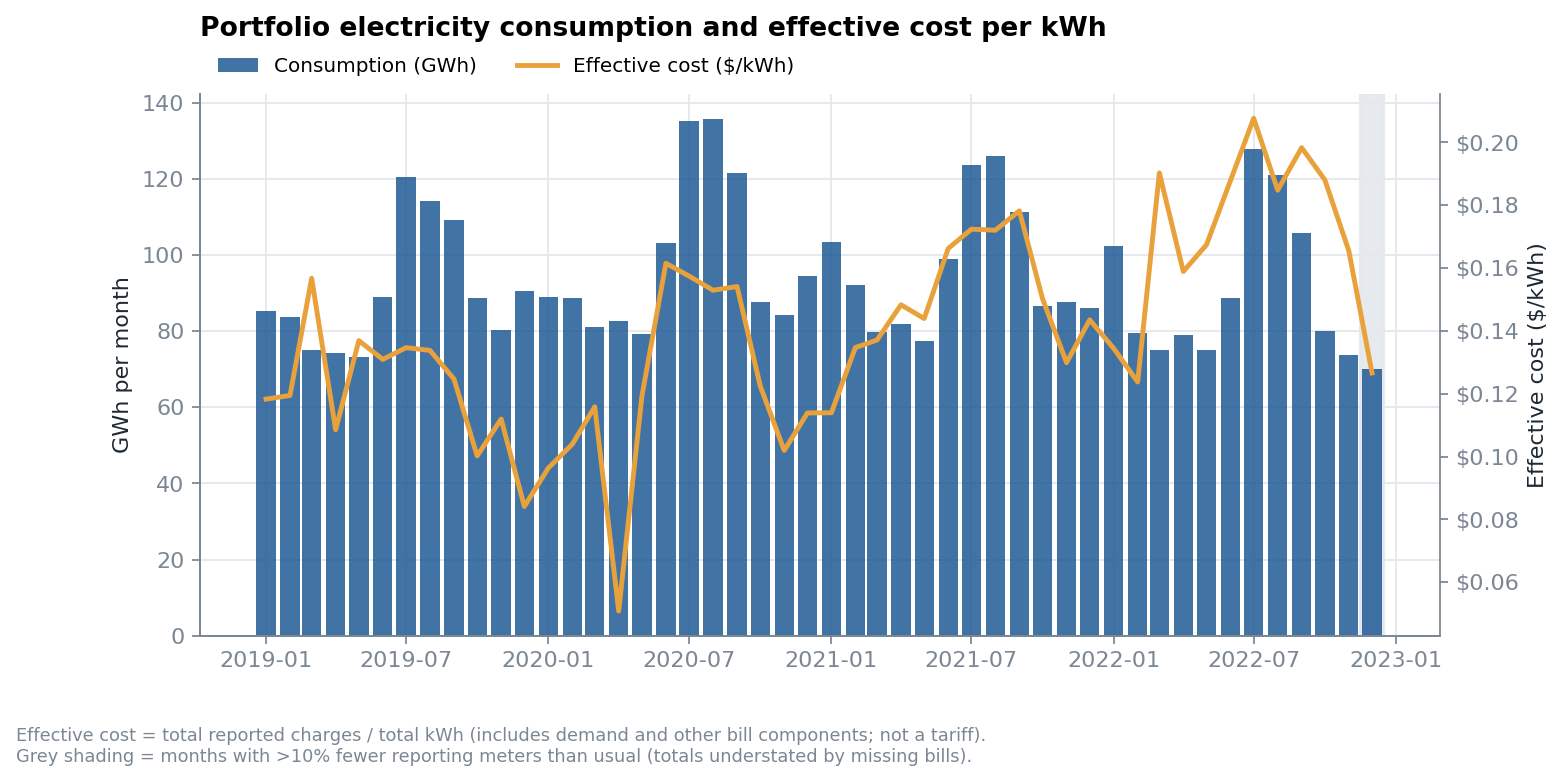

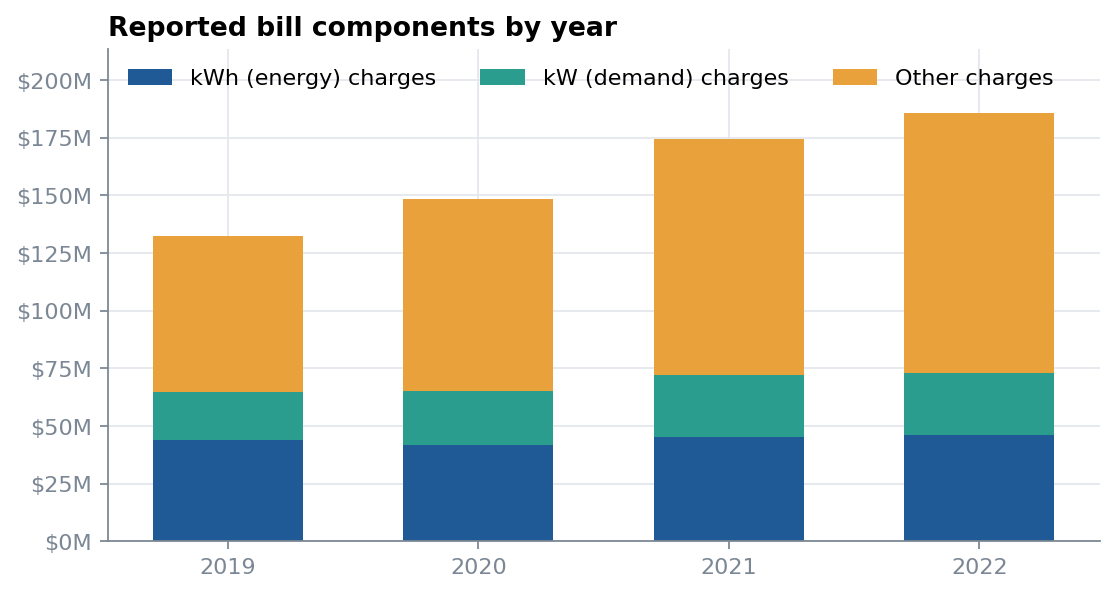

In [4]:
display(Image(str(config.FIGURES / "02_portfolio_trend.png")))
display(Image(str(config.FIGURES / "03_bill_components.png")))

## 2. Where spending is concentrated

In [5]:
cur = dy[dy.year == Y].sort_values("cost", ascending=False).assign(cum_share=lambda d: d.share_of_portfolio_cost.cumsum())
print(f"{(cur.cum_share < .8).sum() + 1} of {len(cur)} developments account for 80% of {Y} spending")
cur.head(10)[["development_name", "borough", "mwh", "cost", "effective_cost_per_kwh", "share_of_portfolio_cost", "cost_yoy"]]

116 of 335 developments account for 80% of 2022 spending


,development_name,borough,mwh,cost,effective_cost_per_kwh,share_of_portfolio_cost,cost_yoy
647,WEST BRIGHTON II,STATEN ISLAND,560,"3,627,164",6.4717,0.0195,50
311,CASTLE HILL,BRONX,"16,002","2,765,699",0.1728,0.0149,0.1141
231,BARUCH,MANHATTAN,"14,737","2,519,035",0.1709,0.0136,0.0018
287,WAGNER,MANHATTAN,"12,875","2,329,689",0.1810,0.0125,-0.0212
339,GRANT,MANHATTAN,"13,034","2,302,377",0.1766,0.0124,0.1494
543,POLO GROUNDS TOWERS,MANHATTAN,"13,004","2,280,500",0.1754,0.0123,0.0893
527,MITCHEL,BRONX,"12,682","2,141,556",0.1689,0.0115,0.1034
203,POMONOK,QUEENS,"11,942","2,127,179",0.1781,0.0115,0.1873
219,EDENWALD,BRONX,"13,285","2,106,746",0.1586,0.0113,0.0694
87,PATTERSON,BRONX,"12,282","2,043,763",0.1664,0.0110,1.1795


In [6]:
dm[dm.year == Y].groupby("borough").agg(mwh=("mwh", "sum"), cost=("cost", "sum")).assign(
    effective_cost_per_kwh=lambda d: d.cost / (d.mwh * 1000), share=lambda d: d.cost / d.cost.sum()).sort_values("cost", ascending=False)

,mwh,cost,effective_cost_per_kwh,share
borough,,,,
BROOKLYN,"338,037","56,407,625",0.1669,0.3037
MANHATTAN,"320,828","54,500,528",0.1699,0.2935
BRONX,"299,753","50,859,618",0.1697,0.2739
QUEENS,"87,171","15,251,537",0.1750,0.0821
STATEN ISLAND,"32,424","8,699,254",0.2683,0.0468


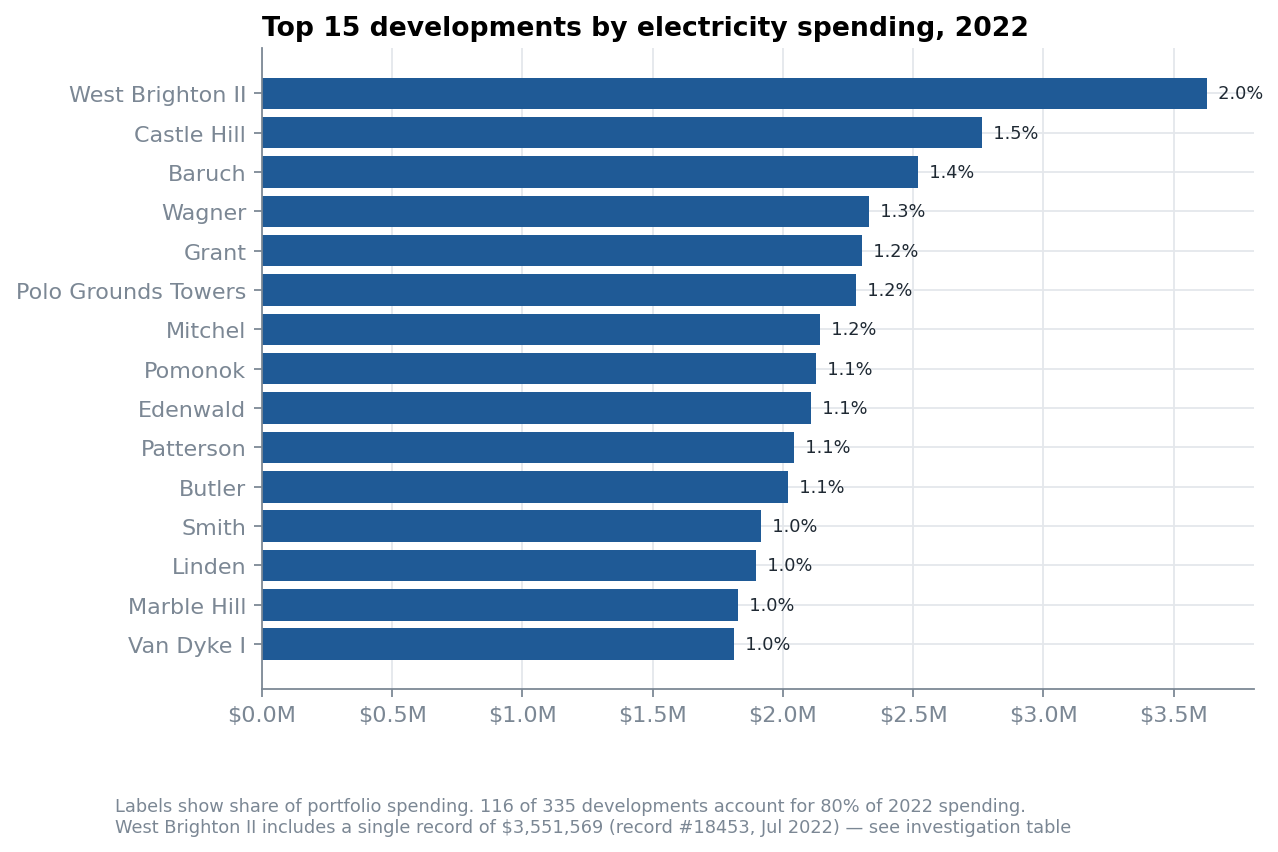

In [7]:
display(Image(str(config.FIGURES / "05_spend_concentration.png")))

## 3. What drove the change in spending

For each development and calendar month, the change is compared with the same month a year earlier:

$$\text{Consumption effect}=(Q_1-Q_0)\,R_0 \qquad \text{Effective-cost effect}=Q_1\,(R_1-R_0)$$

The two effects sum exactly to $C_1-C_0$ whenever both months have kWh > 0. Pairs where a ratio is undefined
(missing month, zero kWh) are reported separately as **non-comparable**, so the bridge still closes.

In [8]:
dec = analysis.yoy_decomposition(dm, Y)
wf = analysis.waterfall_table(dec, Y)
wf

,step,amount,kind,sort_order
0,2021 cost,"174,554,280",total,1
1,Consumption effect,"-2,516,283",delta,2
2,Effective-cost effect,"20,468,886",delta,3
3,Non-comparable (gaps / zero kWh),"-6,788,322",delta,4
4,2022 cost,"185,718,562",total,5


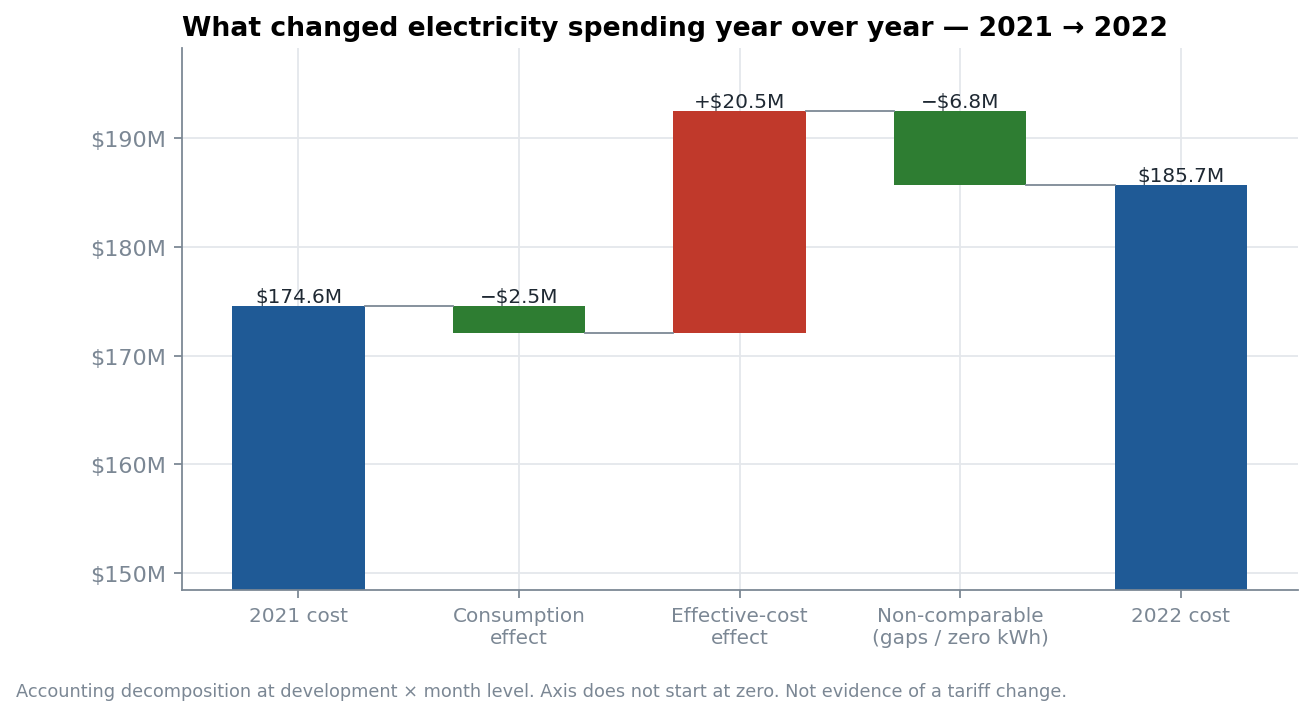

In [9]:
display(Image(str(config.FIGURES / "04_cost_bridge.png")))

In [10]:
c = dec[dec.comparable]
print(f"Like-for-like development-months: {len(c):,} of {len(dec):,}")
print(f"  kWh change:            {c.kwh_cur.sum()/c.kwh_pri.sum()-1:+.1%}   (headline {annual.kwh_yoy.iat[-1]:+.1%})")
print(f"  cost change:           {c.cost_cur.sum()/c.cost_pri.sum()-1:+.1%}   (headline {annual.cost_yoy.iat[-1]:+.1%})")
print(f"  effective cost $/kWh:  {c.cost_pri.sum()/c.kwh_pri.sum():.4f} → {c.cost_cur.sum()/c.kwh_cur.sum():.4f}")

Like-for-like development-months: 3,927 of 4,020
  kWh change:            -2.8%   (headline -6.7%)
  cost change:           +10.7%   (headline +6.4%)
  effective cost $/kWh:  0.1512 → 0.1723


**Reading:** on a like-for-like basis, consumption barely moved. Spending rose because each kWh cost more *all-in*.
The headline consumption decline is mostly a **coverage effect**: developments stop appearing partway through the year.

The bill components show which reported line moved. They cannot show *why* it moved:

In [11]:
analysis.component_change(dm, Y)

,component,prior,current,change,pct_change
0,kwh_charges,"45,177,802","46,075,328","897,525",0.0199
1,kw_charges,"26,845,865","26,954,096","108,231",0.0040
2,other_charges,"102,530,612","112,689,138","10,158,525",0.0991
3,cost,"174,554,280","185,718,562","11,164,282",0.0640
4,kwh,"1,155,440,542","1,078,213,417","-77,227,125",-0.0668
5,kw,"2,697,507","2,120,335","-577,172",-0.2140


In [12]:
# How much of the increase is one record?
big = prep.records.nlargest(1, "current_charges").iloc[0]
inc = annual.cost.iat[-1] - annual.cost.iat[-2]
print(f"Record {big.record_id} ({big.development_name}, {big.revenue_month:%b %Y}): ${big.current_charges:,.0f}")
print(f"= {big.current_charges/inc:.0%} of the {Y} spending increase; cost growth excluding it: "
      f"{(annual.cost.iat[-1]-big.current_charges)/annual.cost.iat[-2]-1:+.1%}")

Record 18453 (WEST BRIGHTON II, Jul 2022): $3,551,569
= 32% of the 2022 spending increase; cost growth excluding it: +4.4%


> This is an accounting decomposition. It shows *where* the arithmetic change sits, not that a tariff changed. The
> effective-cost effect includes supply prices, demand charges, other bill charges, adjustments and possible billing errors.

## 4. Exceptions requiring investigation

Screens applied to every development-month (thresholds in `config.py`):

| Screen | Test |
|---|---|
| Unusual consumption change | Modified z-score of log(kWh / same month last year) vs the development's own history, above 3.5 |
| Unusual effective cost | Development cost/kWh relative to the portfolio that month, scored against its own norm |
| Missing month | No bills, but the development reported in the same month last year |
| Meter-count change | Reporting meters differ from the development's median by more than 10% |
| Spending up, consumption flat | Cost up by at least \$10k while kWh changed by +5% or less |

In [13]:
inv = analysis.investigation_table(dm, pm, years=[Y])
prim = inv[inv.is_primary]
print(f"{len(inv):,} flags on {len(prim):,} development-months in {Y}")
prim.groupby("issue").agg(n=("issue", "size"), net_magnitude=("financial_magnitude", "sum")).sort_values("n", ascending=False)

958 flags on 910 development-months in 2022


,n,net_magnitude
issue,,
Spending up despite stable or falling consumption,485,"10,403,511"
Change in number of reporting meters,205,"445,600"
Unusual consumption change vs same month last year,121,"-1,618,120"
Missing month (reported in same month last year),76,"-6,951,624"
Unusual effective cost per kWh,23,"2,923,423"


In [14]:
pd.set_option("display.max_colwidth", 140)
prim.head(10)[["investigation_id", "development_name", "revenue_month", "issue", "financial_magnitude", "evidence"]]

,investigation_id,development_name,revenue_month,issue,financial_magnitude,evidence
0,INV-0001,WEST BRIGHTON II,2022-07-01,Unusual effective cost per kWh,"3,538,368","$51.108/kWh vs expected $0.190 (portfolio $0.208); credits $0; demand-only rows 1; robust z = +56.5; largest record #18453 ($3,551,569)"
1,INV-0002,MORRISANIA,2022-11-01,Unusual consumption change vs same month last year,"722,393","kWh 2,277 -> 104,130 (+4473%); robust z = +32.3 vs this development's YoY history; meters 2 (typical 2); largest record #8097"
2,INV-0003,RAVENSWOOD,2022-08-01,Missing month (reported in same month last year),"-348,345","No records this month; same month last year cost $348,345"
3,INV-0004,RAVENSWOOD,2022-07-01,Missing month (reported in same month last year),"-343,896","No records this month; same month last year cost $343,896"
4,INV-0005,RAVENSWOOD,2022-09-01,Missing month (reported in same month last year),"-277,181","No records this month; same month last year cost $277,181"
5,INV-0006,WASHINGTON,2022-09-01,Missing month (reported in same month last year),"-242,143","No records this month; same month last year cost $242,143"
6,INV-0007,BAY VIEW,2022-08-01,Change in number of reporting meters,"-241,308","1 meters vs typical 44; cost $247,744 -> $6,436"
8,INV-0009,WASHINGTON,2022-08-01,Missing month (reported in same month last year),"-228,016","No records this month; same month last year cost $228,016"
9,INV-0010,RAVENSWOOD,2022-06-01,Missing month (reported in same month last year),"-224,017","No records this month; same month last year cost $224,017"
10,INV-0011,WASHINGTON,2022-07-01,Missing month (reported in same month last year),"-223,510","No records this month; same month last year cost $223,510"


Two cases show why the wording is "requires investigation" and not "inefficiency":

- **West Brighton II, Jul 2022.** One record prices 69k kWh at \$3.55M, which reads as a billing or entry error.
- **Morrisania, Nov 2022.** The +4,000% "increase" comes from a bad **prior-year** record. The Nov 2021 kWh field holds 2,277,
  which matches that record's kWh *charges* (\$2,276.63). This looks like a dollar value entered in the kWh field.

In [15]:
cols = ["record_id", "revenue_month", "meter_number", "kwh", "kwh_charges", "current_charges"]
r = prep.records
r[(r.development_name == "MORRISANIA") & (r.revenue_month.dt.month == 11) & (r.kwh > 0)][cols]

,record_id,revenue_month,meter_number,kwh,kwh_charges,current_charges
5686,8097,2022-11-01,2786053_B013000-58.5%,"104,130","4,031","11,824"
44895,50245,2021-11-01,2786053_B013000-58.5%,"2,277","2,277","5,810"
86106,97441,2020-11-01,2786053_B013000-58.5%,"105,534","3,554","7,554"
125715,150165,2019-11-01,8096662-58.5,"106,002","4,023","9,096"


## 5. Missing developments

Several developments stop reporting partway through the year. The dataset cannot say why. The possibilities are a
portfolio or management change, an account transfer, or release timing. Each needs confirmation with the data owner
before these months are treated as lower demand.

In [16]:
miss = dm[dm.year == Y].groupby(["development_name", "borough"]).is_missing_month.sum()
miss[miss > 0].sort_values(ascending=False).head(10).to_frame("missing_months")

,,missing_months
development_name,borough,
OCEAN BAY APARTMENTS (BAYSIDE),QUEENS,12
ALBANY,BROOKLYN,11
WASHINGTON,MANHATTAN,11
ALBANY II,BROOKLYN,11
SHEEPSHEAD BAY,BROOKLYN,11
RAVENSWOOD,QUEENS,11
FIRST HOUSES,MANHATTAN,4
INGERSOLL,BROOKLYN,3
WAGNER,MANHATTAN,2
